# Exploratory Data Analysis: Global Supply Chain Resilience

**CIS 9655 Data Visualization, Baruch College.** Team: Jason Braverman, Paven Oommen, Supriya Singh, Raul Sola Navarro.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RaulSolaNavarro/cis9655-supply-chain/blob/main/eda/CIS9655_EDA_Supply_Chain_Resilience.ipynb)

**What this notebook is for.** Before we built the Tableau Story we pulled the data, checked it, and decided how to chart it. This notebook walks through that exploration in order, so a reader can see what the data looks like, where it is messy, and why we made the choices we did. It was written up after the build, so every number here is recomputed from the frozen snapshots in the repo and checked against the figures in the deck.

**How to run it.** Click the Colab badge, then *Runtime > Run all*. No API key and no uploads are needed: the notebook reads the frozen CSV snapshots straight from our public GitHub repo. Run time is under a minute.

**Sections**

| # | Section | Question it answers |
|---|---|---|
| 1 | Setup | Which libraries, constants, and disruption windows do we use? |
| 2 | Load the data | What files do we read, and where do they come from? |
| 3 | First look | What does each table contain (shape, columns, types)? |
| 4 | Data quality | Are there gaps, duplicates, odd values, or coverage limits? |
| 5 | Pressure (Q1) | What does the NY Fed pressure score look like across the windows? |
| 6 | Lanes (Q2) | How is lane share built, and how stable is it? |
| 7 | Ports (Q3) | What do ships waiting and port volume look like? |
| 8 | Relationships (Q4) | Do freight rates or pressure lead the lane share? |
| 9 | Datasets we did not use | What else is in the repo, and why did we leave it out? |
| 10 | Findings | What did the exploration tell us, and what are the limits? |

For the definition of every column, metric and source, see [`data/DATA_DEFINITIONS.md`](https://github.com/RaulSolaNavarro/cis9655-supply-chain/blob/main/data/DATA_DEFINITIONS.md).

## 1. Setup

We import the libraries, set the constants that every later section shares, and define the four disruption windows. The windows are the same ones used in every chart in the project (`q1-pressure/build_gscpi_chart.py`), so numbers here match the deck.

In [1]:
# os lets us read an optional environment variable (used only for offline testing, see below).
import os

# pandas does the table work; numpy gives us a few math helpers.
import pandas as pd
import numpy as np

# matplotlib draws the charts. mdates formats the date axes.
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# display() prints a DataFrame as a nicely formatted table in Colab/Jupyter.
from IPython.display import display

# Show up to 40 columns and 60 rows, and round floats to 2 decimals, so tables stay readable.
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# Make every figure a sensible default size and give it a clean look.
plt.rcParams.update({
    "figure.figsize": (11, 4.2),   # width x height in inches
    "axes.spines.top": False,      # remove the top border of each chart
    "axes.spines.right": False,    # remove the right border of each chart
    "axes.grid": True,             # light gridlines make values easier to read
    "grid.color": "#e4e3df",       # a pale gray for the gridlines
    "font.size": 10,
})

In [2]:
# ---- Where the data lives -------------------------------------------------
# The repo is public, so Colab can read the CSV snapshots straight from GitHub.
GITHUB_RAW = "https://raw.githubusercontent.com/RaulSolaNavarro/cis9655-supply-chain/main"

# If you cloned the repo and want to run this offline, set the environment variable
# EDA_LOCAL_ROOT to the repo folder. Otherwise this stays None and we read from GitHub.
LOCAL_ROOT = os.environ.get("EDA_LOCAL_ROOT")

# The snapshots are dated. This is the pull date in every file name (YYYY-MM-DD).
SNAPSHOT = "2026-10-15"


def read(rel_path, **kwargs):
    # Build the full location: a local folder if LOCAL_ROOT is set, GitHub otherwise.
    base = LOCAL_ROOT if LOCAL_ROOT else GITHUB_RAW
    # pd.read_csv accepts either a file path or a URL, so one line covers both cases.
    return pd.read_csv(f"{base}/{rel_path}", **kwargs)

In [3]:
# ---- Project-wide constants (same values as the q1-q4 build scripts) -------

# Disruption windows: (name, first month, last month). A last month of None means "to the latest data".
# The Panama drought and Red Sea windows overlap from Nov 2023 to May 2024, so those months sit in both.
WINDOWS = [
    ("West Coast port congestion", "2021-01", "2022-12"),
    ("Panama Canal drought",       "2023-06", "2024-05"),
    ("Red Sea / Suez rerouting",   "2023-11", "2024-12"),
    ("Renewed 2026 pressure",      "2026-01", None),
]

START = "2019-01-01"            # all three sources are compared from January 2019 onward
BASELINE = ("2019-01", "2019-12")  # 2019 is our "normal" year (before the pandemic shock)
SMOOTH_MONTHS = 3               # rolling-average length used for lane share and port volume
ELEVATED = 1.0                  # a GSCPI reading above +1 standard deviation counts as "clearly stressed"

# The exact indicator names BTS uses in its long-format table (copied from the source).
BACKLOG    = "Number of Containerships Awaiting Berths at all U.S. Ports"
ANCHORED   = "Number of Containerships Anchored off U.S. Ports"
LOADED_IMP = "Loaded Import Containers at Select U.S. Ports in TEUs"
LOADED_EXP = "Loaded Export Containers at Select U.S. Ports in TEUs"
EMPTY_EXP  = "Empty Export Containers at Select U.S. Ports in TEUs"
CAPACITY   = "Capacity of Containerships Calling at U.S. Ports (in TEUs)"
FREIGHT    = "Freight Rates in $ per 40ft Container from Shanghai to LA"

# Colors: blue = Pacific-direct, orange = Panama-dependent, gray = everything else / windows.
BLUE, ORANGE, GRAY, BAND = "#2a78d6", "#eb6834", "#8a8984", "#d9d8d3"


def bounds(start, end, last):
    # Turn the "YYYY-MM" strings into real timestamps; an open-ended window runs to the last data month.
    lo = pd.Timestamp(start)
    hi = pd.Timestamp(end) if end else last
    return lo, hi


def shade_windows(ax, last):
    # Draw a light gray band behind the chart for each disruption window.
    pad = pd.Timedelta(days=15)  # widen each band by half a month so the first and last month are fully covered
    for _, start, end in WINDOWS:
        lo, hi = bounds(start, end, last)
        ax.axvspan(lo - pad, hi + pad, color=BAND, alpha=0.45, lw=0, zorder=0)

## 2. Load the data

We use three core sources, each frozen as a dated snapshot in `data/processed/`:

| Variable | File | Source | What it holds |
|---|---|---|---|
| `gscpi` | `gscpi_<date>.csv` | NY Fed | One pressure score per month, 1998 to Sep 2026 |
| `bts` | `bts_port_indicators_<date>.csv` | Bureau of Transportation Statistics | Seven port and freight indicators in one long table |
| `lanes` | `census_porths_5700_lanes_<date>.csv` | US Census Bureau | China-origin imports by US port of unlading, monthly from Jan 2019 |

Three more Census files are loaded for context only (section 9). The snapshots never change, so every run gives the same numbers.

In [4]:
# GSCPI: parse_dates turns the "date" text column into real dates so we can sort and slice by time.
gscpi = read(f"data/processed/gscpi_{SNAPSHOT}.csv", parse_dates=["date"])

# BTS indicators: one row per date x indicator x port/region (a "long" table).
bts = read(f"data/processed/bts_port_indicators_{SNAPSHOT}.csv", parse_dates=["date"])

# Census imports from China by port: one row per month x port. "month" stays text (YYYY-MM) for now.
lanes = read(f"data/processed/census_porths_5700_lanes_{SNAPSHOT}.csv")

# Context-only Census files (explored briefly in section 9).
china_hs2   = read(f"data/processed/census_imports_china_hs2_{SNAPSHOT}.csv")
mexico_hs2  = read(f"data/processed/census_exports_mexico_hs2_{SNAPSHOT}.csv")
exports_all = read(f"data/processed/census_exports_all_hs_2013-04_{SNAPSHOT}.csv")

# Confirm the load worked: print each table's name and its (rows, columns) size.
for name, df in [("gscpi", gscpi), ("bts", bts), ("lanes", lanes),
                 ("china_hs2", china_hs2), ("mexico_hs2", mexico_hs2), ("exports_all", exports_all)]:
    print(f"{name:12s} {df.shape[0]:>7,} rows x {df.shape[1]} columns")

gscpi            345 rows x 2 columns
bts            4,930 rows x 6 columns
lanes         24,000 rows x 11 columns
china_hs2     16,072 rows x 10 columns
mexico_hs2    15,908 rows x 10 columns
exports_all   15,254 rows x 8 columns


## 3. First look at each table

For each table we check four things: the first rows, the column types, how many values are missing, and how many distinct values each column has. The helper below does all four, so we can reuse it.

In [5]:
def profile(df, name):
    # Print a header with the table name and its size.
    print(f"=== {name}: {df.shape[0]:,} rows x {df.shape[1]} columns ===")
    # Build a one-row-per-column summary table.
    summary = pd.DataFrame({
        "dtype": df.dtypes.astype(str),                     # how pandas stores the column (number, text, date)
        "non_null": df.notna().sum(),                       # count of filled-in values
        "missing": df.isna().sum(),                         # count of empty values
        "missing_%": (df.isna().mean() * 100).round(1),     # share of the column that is empty
        "unique": df.nunique(),                             # count of distinct values
    })
    display(summary)
    # Show the first three rows so we can see real example values.
    display(df.head(3))


profile(gscpi, "gscpi")

=== gscpi: 345 rows x 2 columns ===


,dtype,non_null,missing,missing_%,unique
date,datetime64[us],345,0,0.00,345
value,float64,345,0,0.00,345


,date,value
0,1998-01-31,-0.79
1,1998-02-28,-0.41
2,1998-03-31,-0.12


**GSCPI** is the simplest table: a month-end `date` and one `value`. There are no missing values. The value is in standard deviations from the series' long-run average, so 0 means an average month.

In [6]:
profile(bts, "bts")

=== bts: 4,930 rows x 6 columns ===


,dtype,non_null,missing,missing_%,unique
date,datetime64[us],4930,0,0.00,781
indicator,str,4930,0,0.00,7
port_or_region,str,4446,484,9.80,15
value,float64,4930,0,0.00,3048
units,str,4930,0,0.00,3
source,str,4930,0,0.00,5


,date,indicator,port_or_region,value,units,source
0,2019-01-06,Capacity of Containerships Calling at U.S. Por...,NaN,"1,692,044.00",TEUs,MARAD Office of Policy and Plans analysis of C...
1,2019-01-13,Capacity of Containerships Calling at U.S. Por...,NaN,"2,032,538.00",TEUs,MARAD Office of Policy and Plans analysis of C...
2,2019-01-20,Capacity of Containerships Calling at U.S. Por...,NaN,"2,037,507.00",TEUs,MARAD Office of Policy and Plans analysis of C...


**BTS** is a long table. The `indicator` column says *what* is measured, and `port_or_region` says *where* (it is empty for system-wide indicators such as the freight rate). Because different indicators have different units and different reporting frequencies, we cannot treat the `value` column as one measure. We break it out by indicator next.

In [7]:
# Group by indicator and summarize its coverage: how many rows, first/last date, how many ports, units.
bts_summary = (bts.groupby("indicator")
                  .agg(rows=("value", "size"),                       # number of observations
                       first=("date", "min"),                        # earliest date
                       last=("date", "max"),                         # latest date
                       ports_or_regions=("port_or_region", "nunique"),  # distinct places (0 = system-wide)
                       units=("units", "first"))                     # unit of measure
                  .sort_values("first"))

# Estimate how often each indicator is reported: the median number of days between consecutive dates.
def cadence_days(g):
    # Use one place at a time so multiple ports on the same date do not look like zero-day gaps.
    one = g[g["port_or_region"] == g["port_or_region"].dropna().iloc[0]] if g["port_or_region"].notna().any() else g
    return one["date"].sort_values().diff().dt.days.median()

# Apply the helper to each indicator and attach the result as a new column.
bts_summary["median_gap_days"] = bts.groupby("indicator").apply(cadence_days, include_groups=False)

display(bts_summary)

,rows,first,last,ports_or_regions,units,median_gap_days
indicator,,,,,,
Empty Export Containers at Select U.S. Ports in TEUs,818,2019-01-01,2026-07-01,9,TEUs,31.00
Loaded Export Containers at Select U.S. Ports in TEUs,818,2019-01-01,2026-07-01,9,TEUs,31.00
Loaded Import Containers at Select U.S. Ports in TEUs,818,2019-01-01,2026-07-01,9,TEUs,31.00
Capacity of Containerships Calling at U.S. Ports (in TEUs),404,2019-01-06,2026-09-27,0,TEUs,7.00
Freight Rates in $ per 40ft Container from Shanghai to LA,80,2020-02-01,2026-09-01,0,Dollars per 40ft box,31.00
Number of Containerships Anchored off U.S. Ports,780,2021-07-27,2026-10-13,3,Number of vessels,7.00
Number of Containerships Awaiting Berths at all U.S. Ports,1212,2021-07-27,2026-10-13,4,Number of vessels,7.00


**What the BTS summary tells us**

- The **weekly** series (ships waiting, ships anchored, ship capacity) have a median gap of 7 days and start in **July 2021** (backlog and anchored) or January 2019 (capacity).
- The **monthly** series (loaded imports, loaded exports, empty exports, freight rate) have a gap of about 30 days. Port TEUs stop in **July 2026**, about three months behind the newest weekly data, so the latest port volume is older than the latest backlog.
- Five of the seven indicators are split by place: the berth backlog (four groups: LA-LB, Savannah, All Other Ports, and an All U.S. Container Ports total), anchored ships (East, Gulf, West coast), and the three TEU series (nine ports each). We use the three backlog groups and leave out the total, because adding the total to its own parts would double count.
- The freight rate and ship capacity have no place column; each is one system-wide number per period.

This is why we roll weekly series up to months and align everything on a shared monthly timeline (a team decision in October).

In [8]:
profile(lanes, "lanes (Census imports from China by port)")

=== lanes (Census imports from China by port): 24,000 rows x 11 columns ===


,dtype,non_null,missing,missing_%,unique
month,str,24000,0,0.00,92
port_code,int64,24000,0,0.00,361
port_name,str,23928,72,0.30,358
bts_port,str,1012,22988,95.80,9
lane_group,str,24000,0,0.00,3
country_name,str,24000,0,0.00,1
total_value_usd,int64,24000,0,0.00,18040
vessel_value_usd,int64,24000,0,0.00,6798
containerized_value_usd,int64,24000,0,0.00,6141
containerized_weight_kg,int64,24000,0,0.00,6045


,month,port_code,port_name,bts_port,lane_group,country_name,total_value_usd,vessel_value_usd,containerized_value_usd,containerized_weight_kg,air_value_usd
0,2019-01,101,"PORTLAND, ME",NaN,Other,CHINA,652227,652227,563503,17798,0
1,2019-01,104,"JACKMAN, ME",NaN,Other,CHINA,136531,0,0,0,0
2,2019-01,106,"HOULTON, ME",NaN,Other,CHINA,316720,0,0,0,0


**Lanes** has 24,000 rows: one per month and port, for 92 months (Jan 2019 to Aug 2026). `bts_port` is filled only for the nine ports that BTS also covers; everything else is `Other`. `port_name` is empty for 72 rows (a few small ports have no name in the Census file), which does not affect our analysis because we group by `lane_group`.

## 4. Data quality checks

Here we test the things that can silently break a chart: missing months, duplicate rows, partial months, a port that drops in and out, and whether our lane totals are complete. Each check prints a clear pass or a list of problems.

In [9]:
# ---- 4a. GSCPI: is every month present exactly once? -----------------------
# Build the list of month-end dates we expect between the first and last row.
expected = pd.date_range(gscpi["date"].min(), gscpi["date"].max(), freq="ME")
# Find any expected month that is not in the data.
missing_months = expected.difference(gscpi["date"])
# Count dates that appear more than once.
dupes = gscpi["date"].duplicated().sum()
print(f"GSCPI: {len(gscpi)} rows, {gscpi['date'].min():%Y-%m} to {gscpi['date'].max():%Y-%m}")
print(f"  missing months: {len(missing_months)}   duplicate dates: {dupes}")

GSCPI: 345 rows, 1998-01 to 2026-09
  missing months: 0   duplicate dates: 0


In [10]:
# ---- 4b. BTS: duplicates and missing values ---------------------------------
# A row is a duplicate if the same date, indicator and port appear twice.
key = ["date", "indicator", "port_or_region"]
print("BTS duplicate rows on (date, indicator, port):", bts.duplicated(key).sum())
print("BTS missing values in 'value':", bts["value"].isna().sum())

# Check for negative values (impossible for counts and dollars) and for zeros (possible: an empty queue).
print("BTS negative values:", (bts["value"] < 0).sum())
zeros = bts[bts["value"] == 0]
print("BTS zero values, by indicator and place:")
display(zeros.groupby(["indicator", "port_or_region"]).size().rename("zero_readings").to_frame())

BTS duplicate rows on (date, indicator, port): 0
BTS missing values in 'value': 0
BTS negative values: 0
BTS zero values, by indicator and place:


zero_readings
indicator                                          port_or_region               
Number of Containerships Anchored off U.S. Ports   Gulf                       34
                                                   West                       31
Number of Containerships Awaiting Berths at all... LA-LB                      76
                                                   Savannah                   24

In [11]:
# ---- 4c. BTS: gaps in the monthly ships-waiting series ----------------------
# Keep the weekly backlog rows for the three groups we chart.
weekly = bts[(bts["indicator"] == BACKLOG) &
             (bts["port_or_region"].isin(["LA-LB", "Savannah", "All Other Ports"]))]

# Turn each weekly date into its calendar month and count how many weekly readings each month has.
readings = weekly.groupby([weekly["date"].dt.to_period("M"), "port_or_region"]).size().unstack()

# List every month between the first and last reading, then find the ones with no data.
all_months = pd.period_range(readings.index.min(), readings.index.max(), freq="M")
no_data = all_months.difference(readings.index)
print("Months with NO ships-waiting readings:", [str(m) for m in no_data])

# Show how many weekly readings the most recent months have, to spot a partial month.
display(readings.tail(4))

Months with NO ships-waiting readings: ['2025-10']


port_or_region,All Other Ports,LA-LB,Savannah
date,,,
2026-07,4,4,4
2026-08,3,3,3
2026-09,4,4,4
2026-10,2,2,2


**Two things to know about the backlog series.**

1. **October 2025 is missing.** BTS published no weekly readings that month, and the file does not say why. We keep the gap as a break in the line instead of filling it, so the chart never invents data.
2. **The newest month can be partial.** The last weekly reading is in mid-October 2026, so October is incomplete. Our monthly roll-up drops a trailing month whose last reading is more than a week before month end. That is why the backlog stops in September 2026 while the raw file runs into October.

A note on zeros: BTS has no negative values, but it does have zero readings. They are real, not errors. They are weeks with no ship waiting at LA-Long Beach (76 weeks) or Savannah (24 weeks), and weeks with no ship anchored off the West or Gulf coast. We keep them, because "nobody waiting" is the story in 2023 to 2026.

In [12]:
# ---- 4d. Lanes: duplicates and the pseudo-port --------------------------------
# One row per month and port code is expected. Any repeat would double-count value.
print("Lanes duplicate (month, port_code) rows:", lanes.duplicated(["month", "port_code"]).sum())

# The processed file already removes the all-ports total row ("-") and "7070 LOW VALUE".
# Confirm neither is still present, because either one would double or distort the totals.
print("Rows for total-row port '-':", (lanes["port_code"].astype(str) == "-").sum())
print("Rows for pseudo-port 7070 :", (lanes["port_code"].astype(str) == "7070").sum())

# Check the months span is complete.
months = pd.period_range(lanes["month"].min(), lanes["month"].max(), freq="M").astype(str)
print("Lane months missing:", sorted(set(months) - set(lanes["month"])) or "none")

Lanes duplicate (month, port_code) rows: 0
Rows for total-row port '-': 0
Rows for pseudo-port 7070 : 0
Lane months missing: none


In [13]:
# ---- 4e. Lanes: does each of the 9 mapped ports appear in every month? ------
# Keep only the rows mapped to a BTS port, then count distinct months per Census port code.
mapped = lanes[lanes["bts_port"].notna()]
coverage = (mapped.groupby(["lane_group", "bts_port", "port_code", "port_name"])["month"]
                  .nunique().rename("months_present").reset_index())
display(coverage)
print(f"Total months in the lane data: {lanes['month'].nunique()}")

,lane_group,bts_port,port_code,port_name,months_present
0,Pacific-direct,Long Beach,2709,"LONG BEACH, CA",92
1,Pacific-direct,Los Angeles,2704,"LOS ANGELES, CA",92
2,Pacific-direct,Oakland,2811,"OAKLAND, CA",92
3,Pacific-direct,Sea-Tac,3001,"SEATTLE, WA",92
4,Pacific-direct,Sea-Tac,3002,"TACOMA, WA",92
5,Panama-dependent,Charleston,1601,"CHARLESTON, SC",92
6,Panama-dependent,Houston,5301,"HOUSTON, TX",92
7,Panama-dependent,NY-NJ,1001,"NEW YORK, NY",92
8,Panama-dependent,NY-NJ,1003,"NEWARK, NJ",92
9,Panama-dependent,Port of VA,1401,"NORFOLK-NEWPORT NEWS, VA",92


Total months in the lane data: 92


Every mapped Census port code appears in all 92 months, and the Census port names are stable. Two BTS ports combine two Census codes: **NY-NJ** is Newark (1003) plus New York (1001), and **Seattle-Tacoma** is Seattle (3001) plus Tacoma (3002). Those pairs are summed when we build the lane share.

In [14]:
# ---- 4f. Lanes: how much of China's containerized cargo do the 9 ports cover? --
# Add up containerized import value by month and lane group (Pacific-direct, Panama-dependent, Other).
by_group = lanes.pivot_table(index="month", columns="lane_group",
                             values="containerized_value_usd", aggfunc="sum")

# Divide each group by the monthly total to get the share of all China containerized imports.
shares_all = by_group.div(by_group.sum(axis=1), axis=0) * 100

# Summarize each group's share across the full period.
display(shares_all.describe().loc[["mean", "min", "max"]])
print("Average share covered by the 9 mapped ports:",
      round(shares_all[["Pacific-direct", "Panama-dependent"]].sum(axis=1).mean(), 1), "%")

lane_group,Other,Pacific-direct,Panama-dependent
mean,6.79,62.27,30.94
min,5.23,49.98,25.66
max,10.53,68.68,39.49


Average share covered by the 9 mapped ports: 93.2 %


The nine mapped ports carry about **93%** of China's containerized import value on average (Pacific-direct about 62%, Panama-dependent about 31%). The remaining 7% (`Other`) is spread over many smaller ports and some inland points. So the lane share we chart is a share of **all** China containerized imports, and the two lane lines add to about 93%, not 100%. That is a small coverage gap, and it means our nine ports are a good picture of where China's boxes land.

In [15]:
# ---- 4g. Why containerized value and not total value? -----------------------
# Add up each value type across all ports by month.
by_type = lanes.groupby("month")[["total_value_usd", "vessel_value_usd",
                                  "containerized_value_usd", "air_value_usd"]].sum()

# Express each type as a percent of total value to see what portion is ocean/container vs air.
mix = by_type.div(by_type["total_value_usd"], axis=0) * 100
display(mix.describe().loc[["mean", "min", "max"]].round(1))

,total_value_usd,vessel_value_usd,containerized_value_usd,air_value_usd
mean,100.00,65.70,63.70,28.80
min,100.00,46.70,45.20,17.10
max,100.00,77.90,75.90,45.20


Total import value includes air freight (about 29% of value on average, and as much as 45% in some months) and ocean cargo that is not in containers. Neither uses the container lanes we care about. Containerized value (about 64% of the total) is the closest field to "boxes crossing the ocean," so it is our lane measure. Using total value would let air freight swings leak into a chart about sea routes.

## 5. Pressure (Q1): the NY Fed Global Supply Chain Pressure Index

**Question:** How big were the pressure spikes in each disruption window, and how long did they last?

We first look at the whole history to learn what "normal" and "extreme" mean for this index, then zoom to 2019 onward.

,count,mean,std,min,25%,50%,75%,max
GSCPI (1998 to now),345.00,0.00,1.01,-1.56,-0.62,-0.28,0.23,4.43


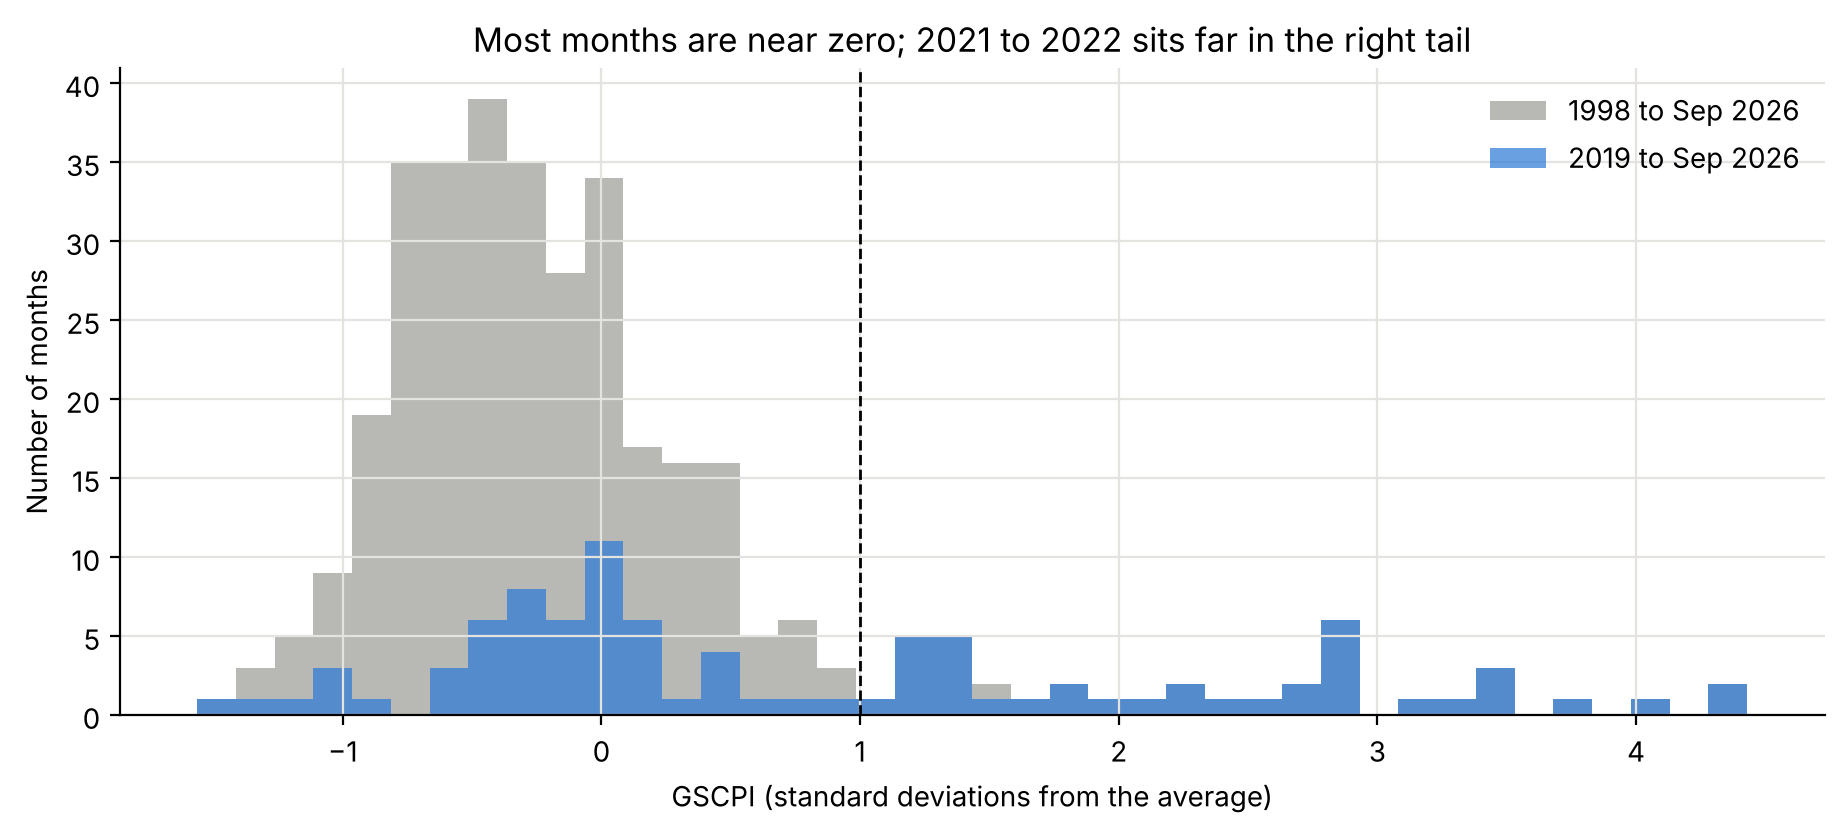

In [16]:
# ---- 5a. Distribution of the full history (1998 to now) ---------------------
# Put the index on dates so slicing by time works.
s_full = gscpi.set_index("date")["value"].sort_index()

# Summary statistics: count, mean, spread, quartiles, min and max.
display(s_full.describe().to_frame("GSCPI (1998 to now)").T)

# Histogram of all monthly values, with the 2019+ values overlaid so we can see where recent months sit.
fig, ax = plt.subplots()
ax.hist(s_full, bins=40, color=GRAY, alpha=0.6, label="1998 to Sep 2026")       # full history in gray
ax.hist(s_full[START:], bins=40, color=BLUE, alpha=0.7, label="2019 to Sep 2026")  # recent period in blue
ax.axvline(ELEVATED, color="black", ls="--", lw=1)                                # our "elevated" line at +1
ax.set_xlabel("GSCPI (standard deviations from the average)")
ax.set_ylabel("Number of months")
ax.set_title("Most months are near zero; 2021 to 2022 sits far in the right tail")
ax.legend(frameon=False)
plt.show()

In [17]:
# ---- 5b. The ten most extreme months on record ------------------------------
# nlargest picks the ten highest values; the result keeps each date as its label.
top10 = s_full.nlargest(10).to_frame("GSCPI")

# Add a z-score column: how many standard deviations this month is from the series' own mean.
top10["z_vs_history"] = (top10["GSCPI"] - s_full.mean()) / s_full.std()
display(top10)

,GSCPI,z_vs_history
date,,
2021-12-31,4.43,4.40
2021-11-30,4.39,4.36
2021-10-31,4.02,4.00
2022-01-31,3.73,3.71
2022-04-30,3.52,3.50
2020-04-30,3.47,3.45
2021-09-30,3.45,3.43
2021-08-31,3.36,3.34
2021-05-31,3.10,3.08


The index is built so that its history averages about zero with a standard deviation near one. Nine of the ten highest months on record fall in 2021 to 2022, led by December 2021 at **4.43**. The tenth is April 2020, the first COVID shock (3.47). Nothing in the 2023 to 2024 windows appears on the list. That is the reason we treat West Coast port congestion as the benchmark episode and the other three windows as smaller by comparison.

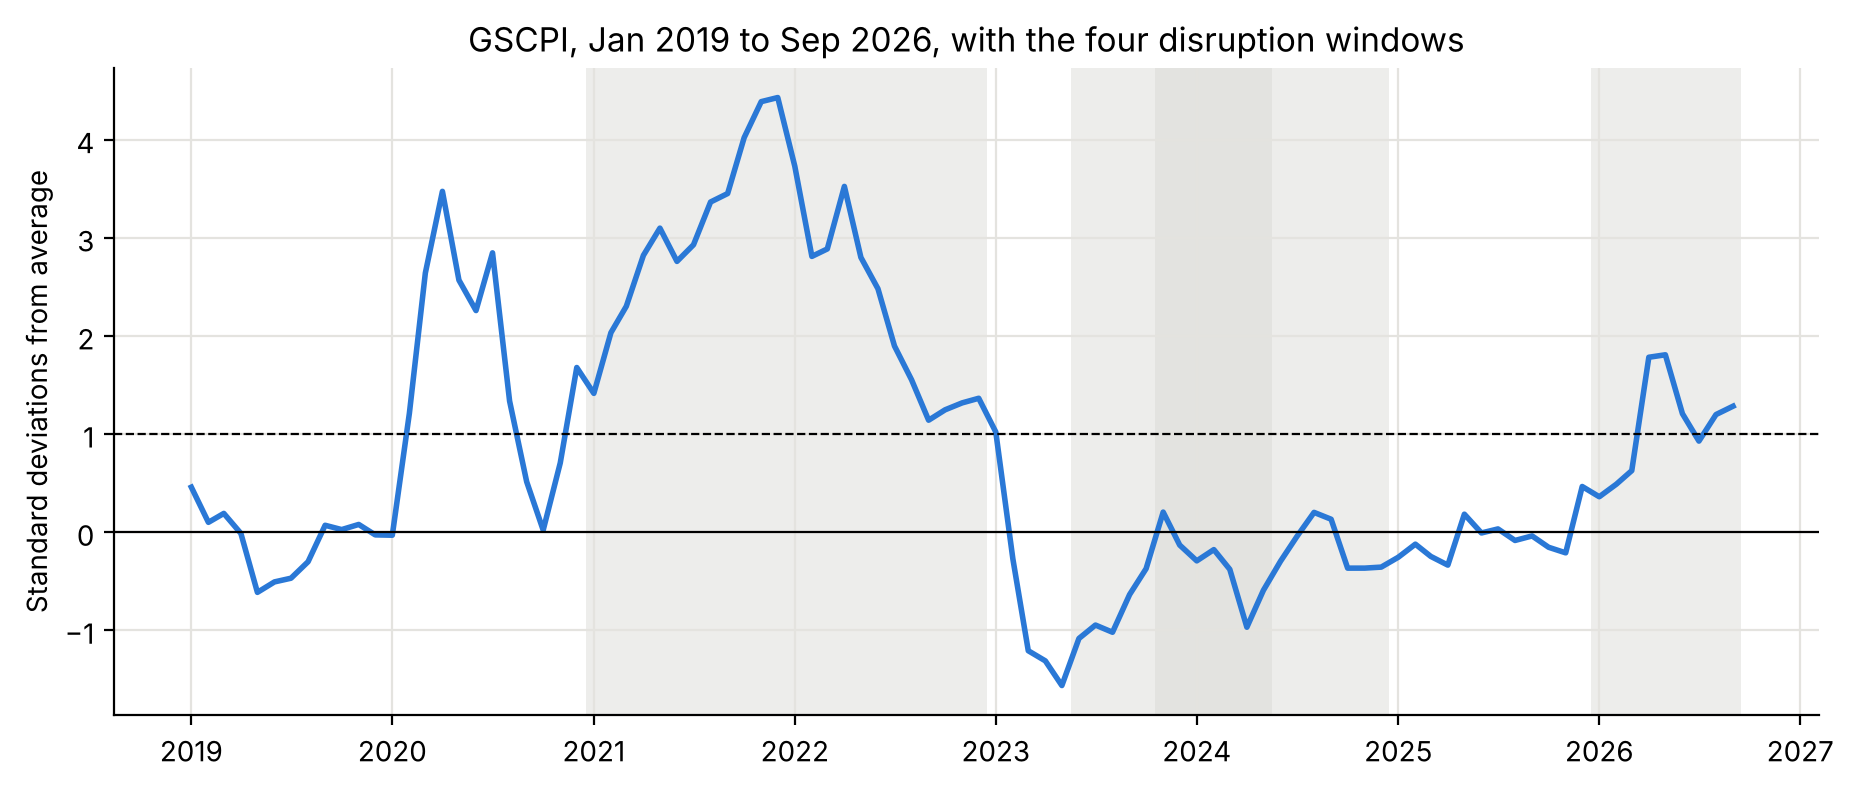

In [18]:
# ---- 5c. The series from 2019 with the disruption windows ------------------
# Slice to January 2019 onward and snap each date to the first of its month so bands line up with points.
s = s_full.copy()
s.index = s.index.to_period("M").to_timestamp()
s = s[START:]

fig, ax = plt.subplots()
shade_windows(ax, s.index[-1])                         # gray bands for the four windows
ax.plot(s.index, s.values, color=BLUE, lw=2)           # the pressure line
ax.axhline(0, color="black", lw=0.8)                   # zero = an average month
ax.axhline(ELEVATED, color="black", lw=0.8, ls="--")   # +1 = clearly stressed
ax.set_title("GSCPI, Jan 2019 to Sep 2026, with the four disruption windows")
ax.set_ylabel("Standard deviations from average")
plt.show()

In [19]:
# ---- 5d. Summary statistics per window ---------------------------------------
rows = []
for name, start, end in WINDOWS:
    # Find the first and last month of this window.
    lo, hi = bounds(start, end, s.index[-1])
    # Slice the series to just that window.
    w = s[lo:hi]
    rows.append({
        "window": name,
        "start": lo.strftime("%Y-%m"),
        "end": hi.strftime("%Y-%m"),
        "months": len(w),                                # window length
        "peak": round(w.max(), 2),                       # highest reading
        "peak_month": w.idxmax().strftime("%Y-%m"),      # when it happened
        "mean": round(w.mean(), 2),                      # average reading
        "months_above_0": int((w > 0).sum()),            # months above an average month
        "months_above_1": int((w > ELEVATED).sum()),     # months clearly stressed
    })
gscpi_windows = pd.DataFrame(rows)
display(gscpi_windows)

,window,start,end,months,peak,peak_month,mean,months_above_0,months_above_1
0,West Coast port congestion,2021-01,2022-12,24,4.43,2021-12,2.66,24,24
1,Panama Canal drought,2023-06,2024-05,12,0.20,2023-11,-0.53,1,0
2,Red Sea / Suez rerouting,2023-11,2024-12,14,0.20,2023-11,-0.25,3,0
3,Renewed 2026 pressure,2026-01,2026-09,9,1.81,2026-05,1.08,9,5


**What we see.** Only two windows are real pressure events by this index. West Coast congestion peaked at 4.43 and stayed above +1 in all 24 months (mean 2.66). The 2026 window peaks at 1.81 (May) and has had 5 of its 9 months above +1. The Panama drought and Red Sea windows peak at only **0.20**, which is barely above an average month, and their averages are below zero. These two were lane-specific shocks that the global index hardly registers, so we cannot use GSCPI alone to explain them. That is why Q2 and Q3 look at where cargo actually went.

## 6. Lanes (Q2): where China's cargo lands

**Question:** Of China-origin containerized imports, how much lands at Pacific-direct ports (Los Angeles, Long Beach, Oakland, Seattle-Tacoma) versus Panama-dependent ports (NY-NJ, Savannah, Virginia, Charleston, Houston)?

We turn dollar values into **shares**, so a lane's line moves only when cargo shifts between lanes, not when China's total volume rises or falls.

In [20]:
# ---- 6a. Build the lane shares -----------------------------------------------
# Same calculation as q2-trade-volume/build_lane_share_chart.py.
# Step 1: sum containerized value by month and lane group.
monthly = lanes.pivot_table(index="month", columns="lane_group",
                            values="containerized_value_usd", aggfunc="sum")

# Step 2: divide each group by that month's total across ALL groups (including "Other"), as a percent.
shares = monthly.div(monthly.sum(axis=1), axis=0) * 100

# Step 3: turn the "YYYY-MM" text index into month-start dates, and keep the two lane groups.
shares.index = pd.PeriodIndex(shares.index, freq="M").to_timestamp()
shares = shares[["Pacific-direct", "Panama-dependent"]]

# Step 4: a 3-month rolling average smooths month-to-month noise.
smooth = shares.rolling(SMOOTH_MONTHS).mean()

display(shares.describe().loc[["count", "mean", "std", "min", "max"]])

lane_group,Pacific-direct,Panama-dependent
count,92.00,92.00
mean,62.27,30.94
std,3.88,3.12
min,49.98,25.66
max,68.68,39.49


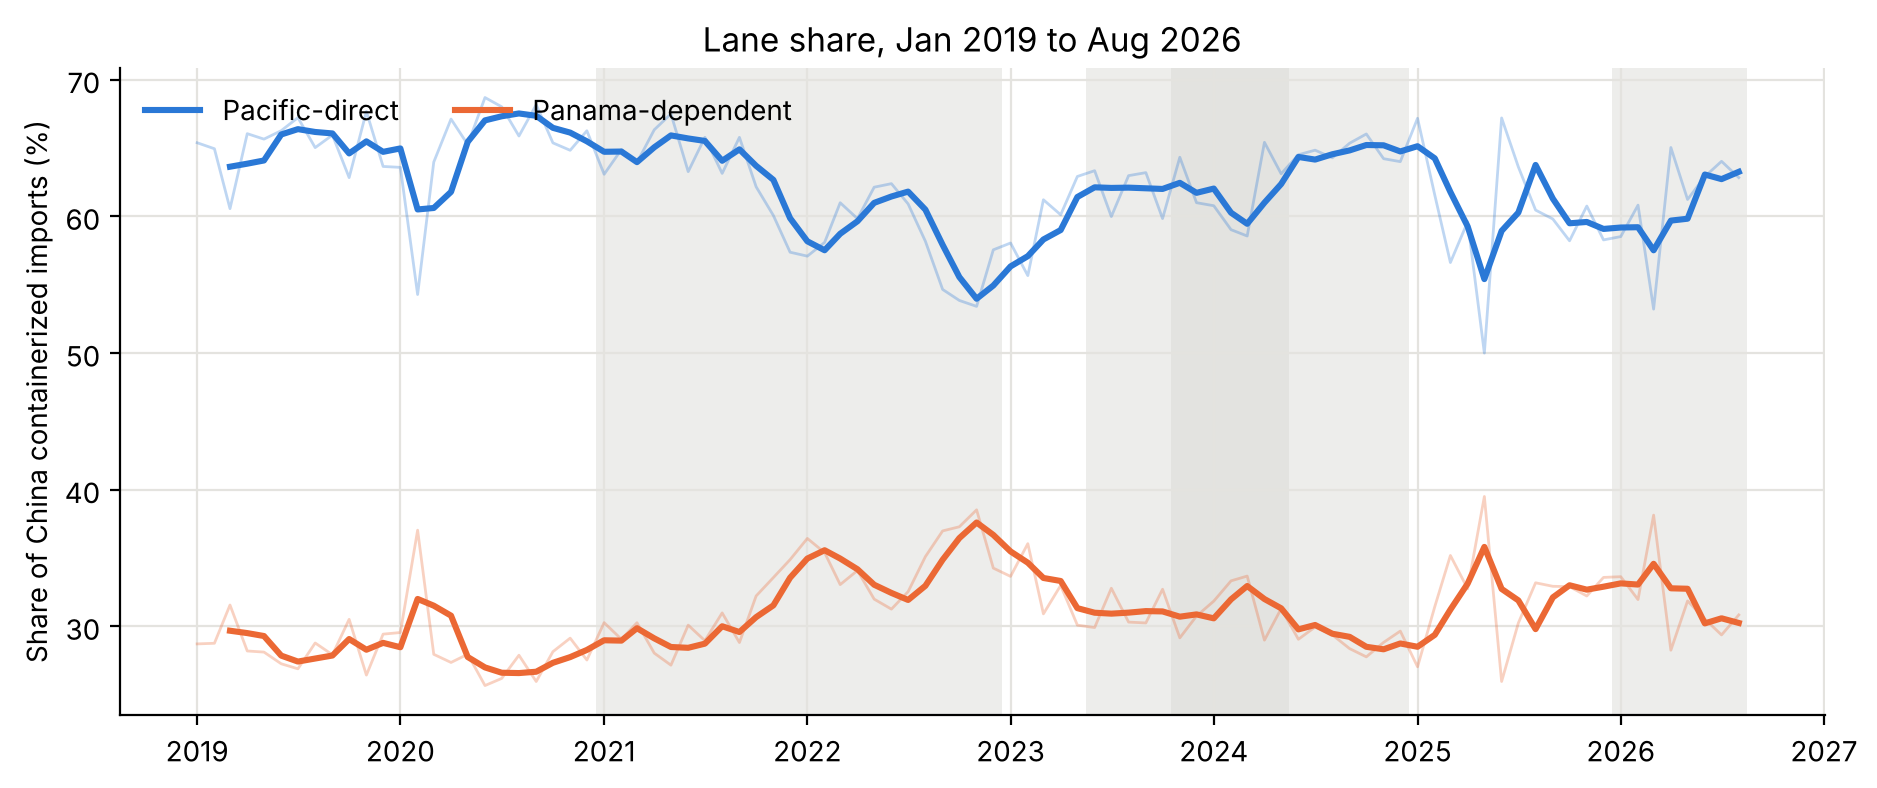

In [21]:
# ---- 6b. Chart: monthly share (faint) and 3-month average (bold) --------------
fig, ax = plt.subplots()
shade_windows(ax, shares.index[-1])
for group, color in [("Pacific-direct", BLUE), ("Panama-dependent", ORANGE)]:
    ax.plot(shares.index, shares[group], color=color, lw=1, alpha=0.3)           # raw monthly values, faint
    ax.plot(smooth.index, smooth[group], color=color, lw=2.2, label=group)       # 3-month average, bold
ax.set_ylabel("Share of China containerized imports (%)")
ax.set_title("Lane share, Jan 2019 to Aug 2026")
ax.legend(frameon=False, ncols=2, loc="upper left")
plt.show()

In [22]:
# ---- 6c. How noisy is one month? Why we smooth. ------------------------------
# Month-to-month change in the raw share, in percentage points.
raw_step = shares["Panama-dependent"].diff().abs()
smooth_step = smooth["Panama-dependent"].diff().abs()
print(f"Typical month-to-month move, raw share:        {raw_step.median():.2f} points (median), max {raw_step.max():.2f}")
print(f"Typical month-to-month move, 3-month average:  {smooth_step.median():.2f} points (median), max {smooth_step.max():.2f}")

Typical month-to-month move, raw share:        1.67 points (median), max 13.54
Typical month-to-month move, 3-month average:  0.65 points (median), max 3.54


The raw monthly share moves by a median of about 1.7 points from one month to the next, against about 0.65 for the 3-month average. A few large shipments landing a week earlier or later can move a single month. Averaging three months keeps real shifts visible and removes much of that timing noise. We still draw the raw months faintly behind the bold line so the viewer can see we have not hidden anything.

In [23]:
# ---- 6d. How much did cargo shift in each window? ------------------------------
# Baseline: the 2019 average share and its normal month-to-month spread.
pan = shares["Panama-dependent"]
base = pan[BASELINE[0]:BASELINE[1]]
print(f"2019 baseline, Panama-dependent share: mean {base.mean():.1f}%, std {base.std():.1f} points")

rows = []
for name, start, end in WINDOWS:
    lo, hi = bounds(start, end, shares.index[-1])
    w = pan[lo:hi]                                           # the window's monthly shares
    # "before" = average of the 3 months right before the window starts.
    before = pan[:lo - pd.Timedelta(days=1)].iloc[-3:].mean()
    # "end" = average of the window's last 3 months.
    end3 = w.iloc[-3:].mean()
    rows.append({
        "window": name,
        "start": lo.strftime("%Y-%m"),
        "end": hi.strftime("%Y-%m"),
        "panama_share_before": round(before, 1),
        "panama_share_end": round(end3, 1),
        "change_pp": round(end3 - before, 1),                # + means cargo moved toward East/Gulf ports
        "panama_share_mean": round(w.mean(), 1),
        "vs_2019_pp": round(w.mean() - base.mean(), 1),      # window average vs the 2019 average
    })
lane_windows = pd.DataFrame(rows)
display(lane_windows)

2019 baseline, Panama-dependent share: mean 28.5%, std 1.5 points


,window,start,end,panama_share_before,panama_share_end,change_pp,panama_share_mean,vs_2019_pp
0,West Coast port congestion,2021-01,2022-12,28.30,36.70,8.40,32.50,4.00
1,Panama Canal drought,2023-06,2024-05,31.30,31.30,-0.00,31.20,2.70
2,Red Sea / Suez rerouting,2023-11,2024-12,31.10,28.70,-2.30,30.10,1.60
3,Renewed 2026 pressure,2026-01,2026-08,32.90,30.20,-2.70,31.80,3.30


**What we see.** Only the 2021 to 2022 port-congestion window moves the share by a lot: **+8.4 points** toward East and Gulf ports. The Panama drought window ends where it started (0.0), and the Red Sea and 2026 windows lean the other way (**−2.3** and **−2.7** points, toward the West Coast). To judge "a lot," we compare with 2019: the share averaged 28.5% with a standard deviation of 1.5 points. So +8.4 is more than five standard deviations, while 2 to 3 points is about 1.5 to 2 standard deviations, a modest but visible shift.

The "vs 2019" column adds a useful caution: the Panama-dependent share stayed 1.6 to 4.0 points above its 2019 average in every window, so cargo never fully returned to its pre-pandemic split.

## 7. Ports (Q3): ships waiting and port volume

**Questions:** Which ports saw the worst congestion, and which recovered fastest? We use two measures:

1. **Ships waiting for a berth** (weekly, from Jul 2021), only available for three groups: LA-Long Beach, Savannah, and all other ports together.
2. **Loaded imports** (monthly TEUs, from 2019), available for each of the nine ports. We convert it to an index where each port's own 2019 average equals 100.

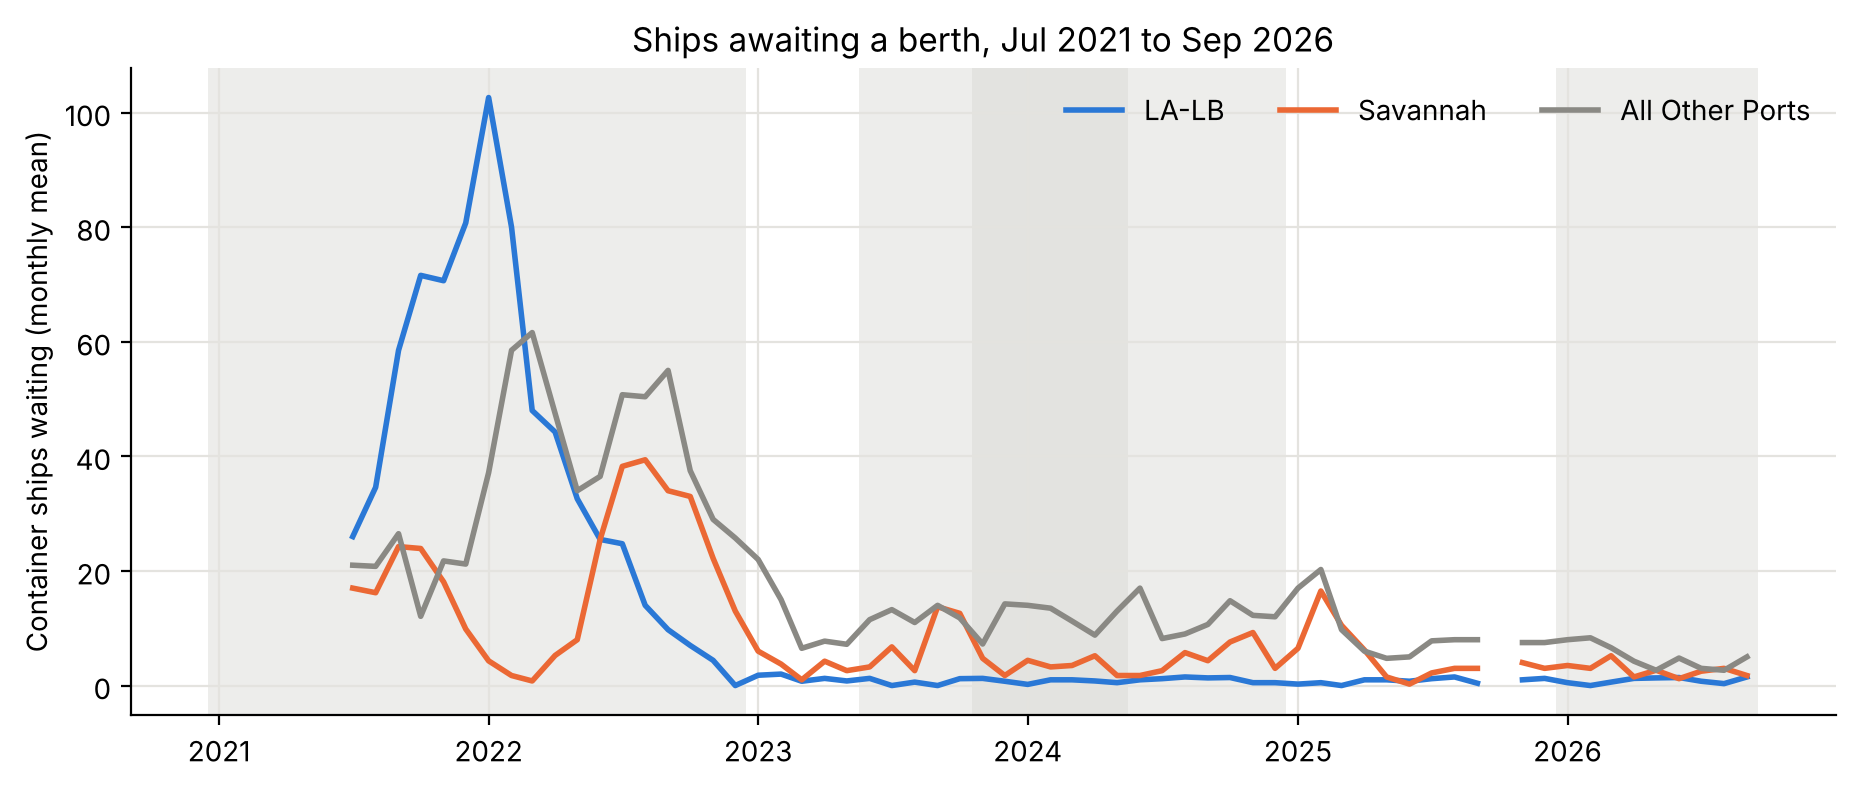

In [24]:
# ---- 7a. Ships waiting for a berth, monthly -------------------------------------
# Keep the weekly backlog rows for the three published groups.
groups = ["LA-LB", "Savannah", "All Other Ports"]
wk = bts[(bts["indicator"] == BACKLOG) & (bts["port_or_region"].isin(groups))].copy()

# Drop a trailing partial month: if the last reading is more than 7 days before month end, remove that month.
last_obs = wk["date"].max()
month = wk["date"].dt.to_period("M")
if (last_obs.to_period("M").end_time - last_obs).days > 7:
    wk = wk[month < last_obs.to_period("M")]

# Average the weekly readings within each month, one column per group.
backlog = wk.pivot_table(index=wk["date"].dt.to_period("M"), columns="port_or_region",
                         values="value", aggfunc="mean")

# Reinsert missing months as empty rows (so the Oct 2025 gap shows as a break), then use month-start dates.
backlog = backlog.reindex(pd.period_range(backlog.index[0], backlog.index[-1], freq="M"))
backlog.index = backlog.index.to_timestamp()
backlog = backlog[groups]

fig, ax = plt.subplots()
shade_windows(ax, backlog.index[-1])
for g, c in zip(groups, [BLUE, ORANGE, GRAY]):
    ax.plot(backlog.index, backlog[g], color=c, lw=2, label=g)
ax.set_ylabel("Container ships waiting (monthly mean)")
ax.set_title("Ships awaiting a berth, Jul 2021 to Sep 2026")
ax.legend(frameon=False, ncols=3, loc="upper right")
plt.show()

In [25]:
# ---- 7b. Peak and recovery for each group ---------------------------------------
CLEARED_FRACTION = 0.25   # a backlog counts as "cleared" once it falls below 25% of its peak

rows = []
for g in groups:
    series = backlog[g].dropna()                 # drop the one missing month for this calculation
    peak_month = series.idxmax()                 # month of the peak
    after = series[peak_month:]                  # everything from the peak onward
    cleared = after[after < series.max() * CLEARED_FRACTION]   # months below 25% of the peak
    rows.append({
        "group": g,
        "peak_ships": round(series.max(), 1),
        "peak_month": peak_month.strftime("%Y-%m"),
        "cleared_month": cleared.index[0].strftime("%Y-%m") if len(cleared) else "",
        "latest_ships": round(series.iloc[-1], 1),
    })
display(pd.DataFrame(rows))

,group,peak_ships,peak_month,cleared_month,latest_ships
0,LA-LB,102.60,2022-01,2022-06,1.50
1,Savannah,39.40,2022-08,2023-01,1.80
2,All Other Ports,61.60,2022-03,2023-02,5.00


LA-Long Beach carried the largest backlog (about **103 ships** in January 2022) and cleared by mid-2022. All Other Ports peaked at about 62 (March 2022). Savannah built its own much smaller peak (about 39 ships in August 2022) once cargo had been diverted east. The latest readings are about 1.5 ships at LA-Long Beach, 1.8 at Savannah and 5 across all other ports. That fits the 2026 story: pressure is high, but ports are not queuing.

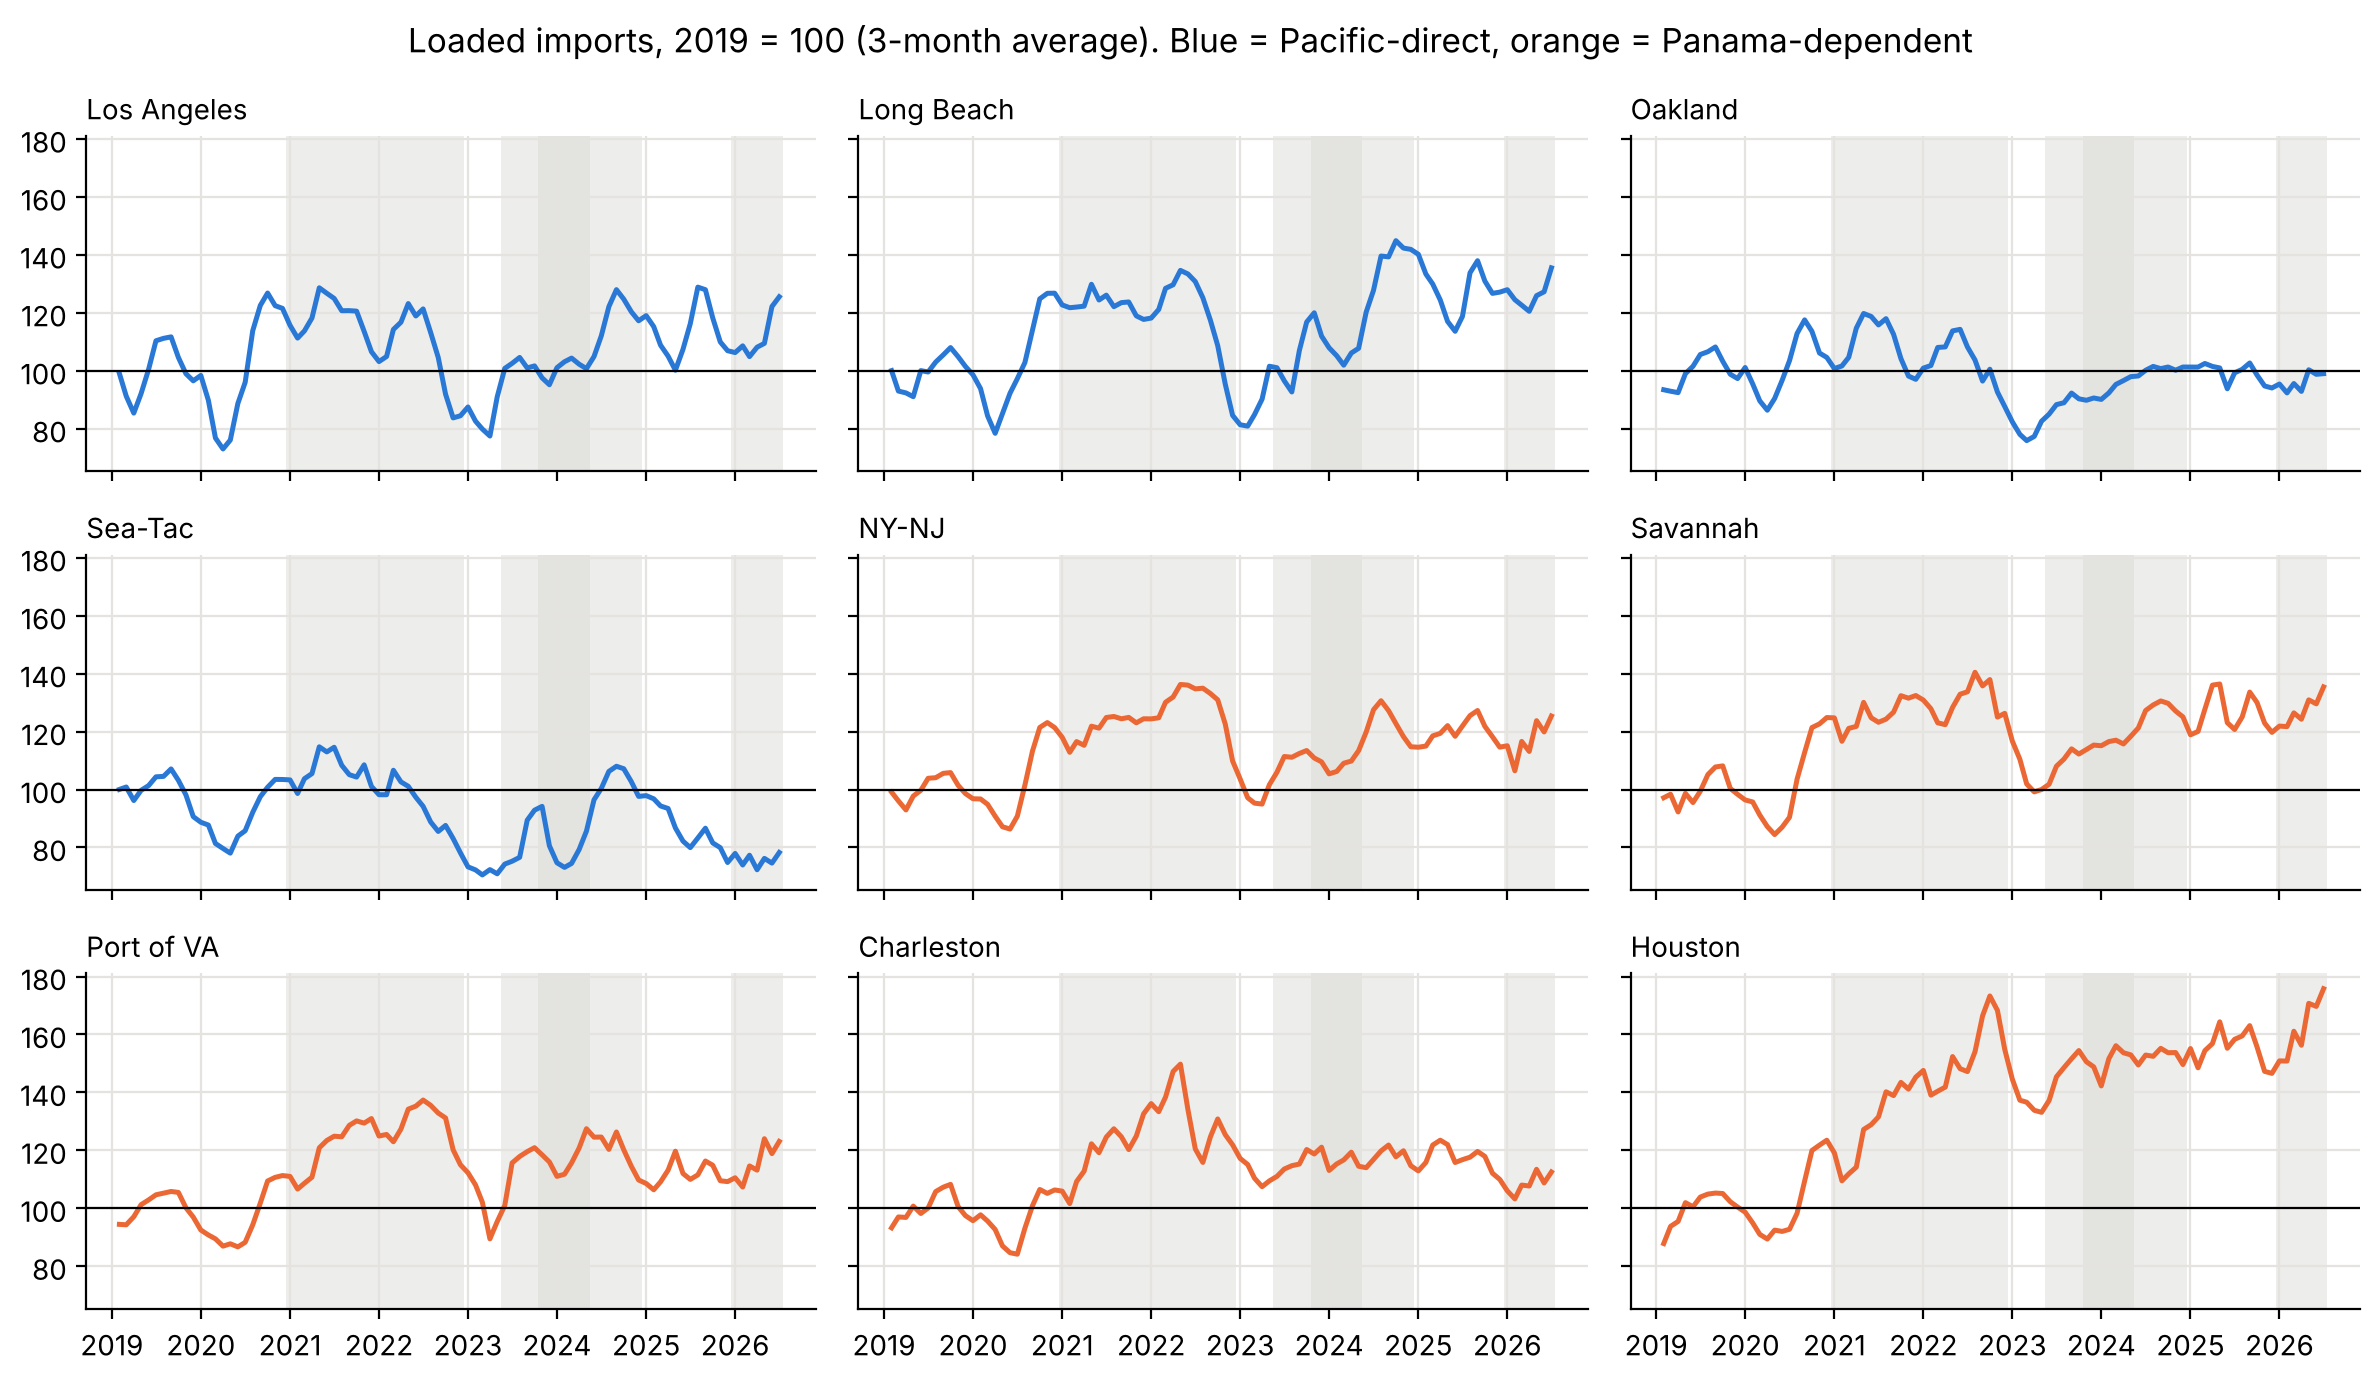

In [26]:
# ---- 7c. Port volume: loaded imports as an index (own 2019 average = 100) ---------
# Pull the loaded-import TEU rows and spread ports into columns, one row per month.
teu = (bts[bts["indicator"] == LOADED_IMP]
       .pivot_table(index="date", columns="port_or_region", values="value"))
teu.index = teu.index.to_period("M").to_timestamp()   # month-start dates

# Divide each port by its own 2019 average, times 100. A value of 80 means 20% below 2019.
index = teu / teu.loc["2019"].mean() * 100

# Smooth with a 3-month rolling average (min_periods=2 lets the very first months still show).
index_smooth = index.rolling(SMOOTH_MONTHS, min_periods=2).mean()

# Small multiples: one panel per port, ordered Pacific-direct first, then Panama-dependent.
order = ["Los Angeles", "Long Beach", "Oakland", "Sea-Tac",
         "NY-NJ", "Savannah", "Port of VA", "Charleston", "Houston"]
lane_of = lanes.dropna(subset=["bts_port"]).drop_duplicates("bts_port").set_index("bts_port")["lane_group"]

fig, axes = plt.subplots(3, 3, figsize=(12, 7), sharex=True, sharey=True)
for ax, port in zip(axes.flat, order):
    color = BLUE if lane_of[port] == "Pacific-direct" else ORANGE
    shade_windows(ax, index_smooth.index[-1])
    ax.plot(index_smooth.index, index_smooth[port], color=color, lw=1.8)
    ax.axhline(100, color="black", lw=0.8)             # 100 = the port's own 2019 level
    ax.set_title(port, fontsize=10, loc="left")
fig.suptitle("Loaded imports, 2019 = 100 (3-month average). Blue = Pacific-direct, orange = Panama-dependent")
fig.tight_layout()
plt.show()

In [27]:
# ---- 7d. Trough and recovery for each port ----------------------------------------
TROUGH_SEARCH = ("2022-07", "2023-12")   # look for each port's low point after the congestion peak

rows = []
for port in order:
    s_p = index_smooth[port].dropna()
    search = s_p[TROUGH_SEARCH[0]:TROUGH_SEARCH[1]]          # the search period
    trough_month = search.idxmin()                           # the month of the lowest reading
    after = s_p[trough_month:]                               # from the low point onward
    back_above = after[after >= 100]                         # months at or above 2019 volume
    rows.append({
        "port": port,
        "lane_group": lane_of[port],
        "trough_index": round(search.min(), 0),              # lowest value (100 = 2019 level)
        "trough_month": trough_month.strftime("%Y-%m"),
        "months_to_recover": ((back_above.index[0].year - trough_month.year) * 12
                              + back_above.index[0].month - trough_month.month)
                             if search.min() < 100 and len(back_above) else (0 if search.min() >= 100 else None),
        "latest_index": round(s_p.iloc[-1], 0),
        "latest_month": s_p.index[-1].strftime("%Y-%m"),
    })
port_stats = pd.DataFrame(rows)
display(port_stats)

,port,lane_group,trough_index,trough_month,months_to_recover,latest_index,latest_month
0,Los Angeles,Pacific-direct,77.00,2023-04,2,126.00,2026-07
1,Long Beach,Pacific-direct,81.00,2023-02,3,136.00,2026-07
2,Oakland,Pacific-direct,76.00,2023-03,16,99.00,2026-07
3,Sea-Tac,Pacific-direct,71.00,2023-03,16,78.00,2026-07
4,NY-NJ,Panama-dependent,95.00,2023-04,1,125.00,2026-07
5,Savannah,Panama-dependent,99.00,2023-04,1,135.00,2026-07
6,Port of VA,Panama-dependent,89.00,2023-04,2,123.00,2026-07
7,Charleston,Panama-dependent,107.00,2023-04,0,113.00,2026-07
8,Houston,Panama-dependent,133.00,2023-05,0,176.00,2026-07


**What we see.** The Pacific-direct ports had the deepest slumps (Seattle-Tacoma bottomed at about 71, Oakland and Los Angeles in the high 70s), while Charleston and Houston never fell below their 2019 volume after 2022. Most ports recovered within a few months, but **Oakland and Seattle-Tacoma took 16 months**, and Seattle-Tacoma is the one port still clearly below 2019 today (index about 78). Note that a drop in volume is not the same thing as congestion: the 2023 slump also reflects weaker import demand, which is why we pair this measure with ships waiting.

## 8. Relationships (Q4): does anything lead the lane share?

**Question:** Does the Shanghai to Los Angeles freight rate, or the pressure score, move *before* cargo shifts between lanes? We test this with correlations at different lags, then check how much to trust them.

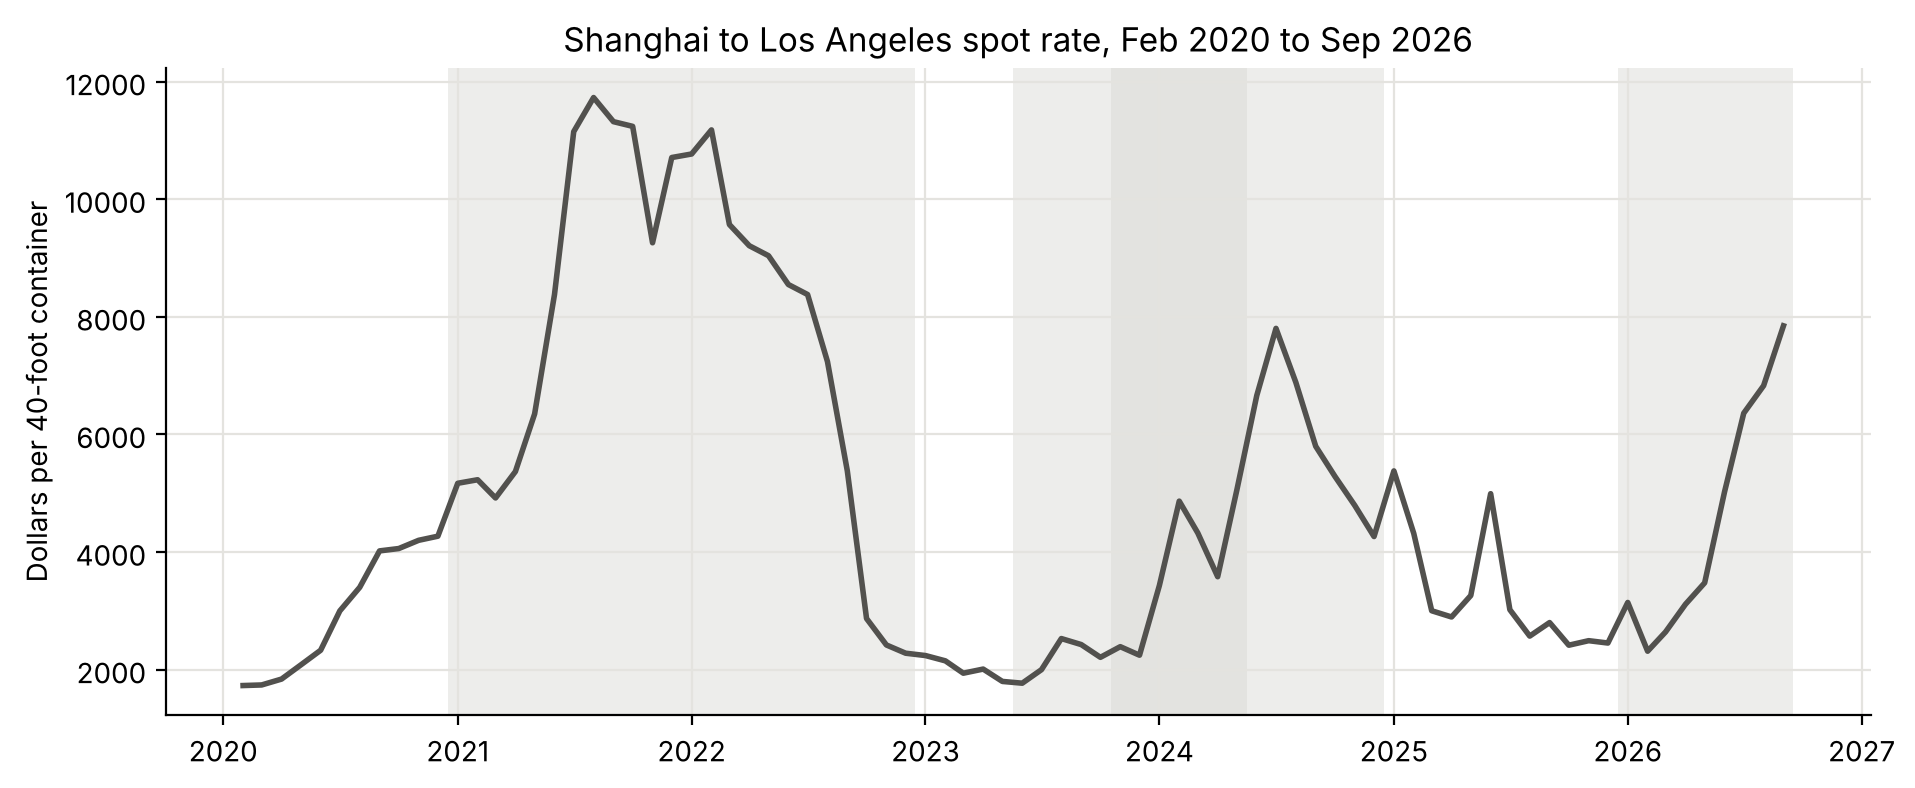

Rate range: $1,730 to $11,730; latest $7,848 (Sep 2026)


In [28]:
# ---- 8a. The freight-rate series ------------------------------------------------
# Pull the monthly Shanghai to LA rate and put it on month-start dates.
rate = bts[bts["indicator"] == FREIGHT].set_index("date")["value"].sort_index()
rate.index = rate.index.to_period("M").to_timestamp()

fig, ax = plt.subplots()
shade_windows(ax, rate.index[-1])
ax.plot(rate.index, rate.values, color="#52514e", lw=2)
ax.set_ylabel("Dollars per 40-foot container")
ax.set_title("Shanghai to Los Angeles spot rate, Feb 2020 to Sep 2026")
plt.show()

print(f"Rate range: ${rate.min():,.0f} to ${rate.max():,.0f}; latest ${rate.iloc[-1]:,.0f} ({rate.index[-1]:%b %Y})")

driver,freight_rate,gscpi
lag_months,,
0,0.02,0.08
1,0.15,0.09
2,0.25,0.12
3,0.32,0.18
4,0.40,0.20
5,0.42,0.23
6,0.48,0.28
7,0.51,0.31
8,0.51,0.35


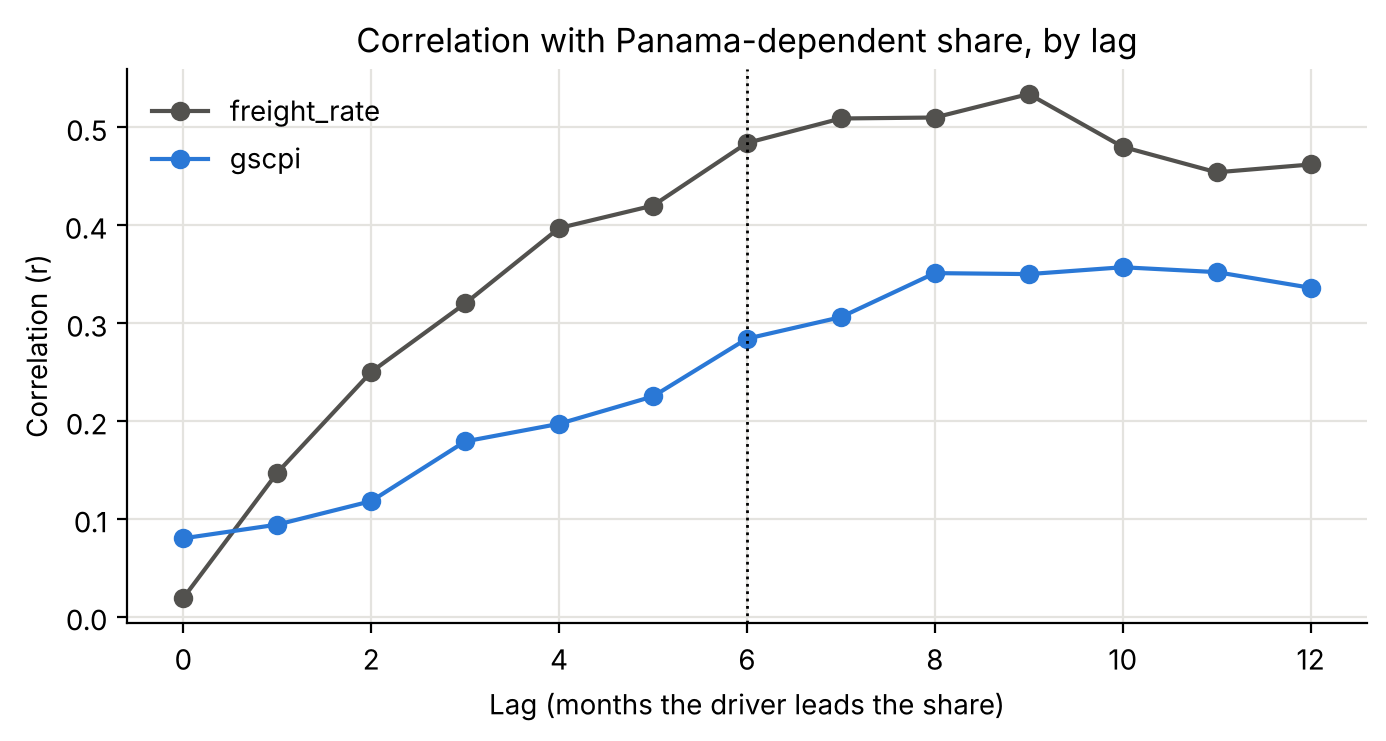

In [29]:
# ---- 8b. Lagged correlations ------------------------------------------------------
# We ask: does the rate (or GSCPI) at month t-lag correlate with the Panama-dependent share at month t?
panama_share = shares["Panama-dependent"]          # from section 6
gscpi_m = s                                        # GSCPI from section 5 (month-start dates)

rows = []
for driver_name, driver in [("freight_rate", rate), ("gscpi", gscpi_m)]:
    for lag in range(0, 13):                        # 0 to 12 months
        shifted = driver.copy()
        # Move the driver's dates forward by `lag` months so a rate in January lines up with a share in July (lag 6).
        shifted.index = shifted.index + pd.DateOffset(months=lag)
        # Keep only months where both series exist, then drop any blanks.
        pair = pd.concat([shifted, panama_share], axis=1, join="inner").dropna()
        rows.append({"driver": driver_name, "lag_months": lag, "n": len(pair),
                     "r": round(pair.iloc[:, 0].corr(pair.iloc[:, 1]), 3)})   # Pearson correlation
lag_table = pd.DataFrame(rows)

# Show both drivers side by side, one row per lag.
display(lag_table.pivot(index="lag_months", columns="driver", values="r"))

# Plot r against lag for each driver.
fig, ax = plt.subplots(figsize=(8, 3.6))
for d, c in [("freight_rate", "#52514e"), ("gscpi", BLUE)]:
    sub = lag_table[lag_table["driver"] == d]
    ax.plot(sub["lag_months"], sub["r"], marker="o", color=c, label=d)
ax.axvline(6, color="black", ls=":", lw=1)
ax.set_xlabel("Lag (months the driver leads the share)")
ax.set_ylabel("Correlation (r)")
ax.set_title("Correlation with Panama-dependent share, by lag")
ax.legend(frameon=False)
plt.show()

At a six-month lag the freight rate has **r = 0.48** with the Panama-dependent share (n = 73 months), and the pressure score has r = 0.28. The pitch deck quoted roughly 0.45, so the headline survived the full data. But the curve is a slow rise (from 0.02 at lag 0 to about 0.53 at nine months), not a sharp peak, so "six months" is a convenient round number rather than a discovery. Before leaning on this we stress-test it.

All months:        r = 0.48  (n = 73)
Through Dec 2022:  r = 0.82  (n = 29)
From Jan 2023 on:  r = 0.09  (n = 44)


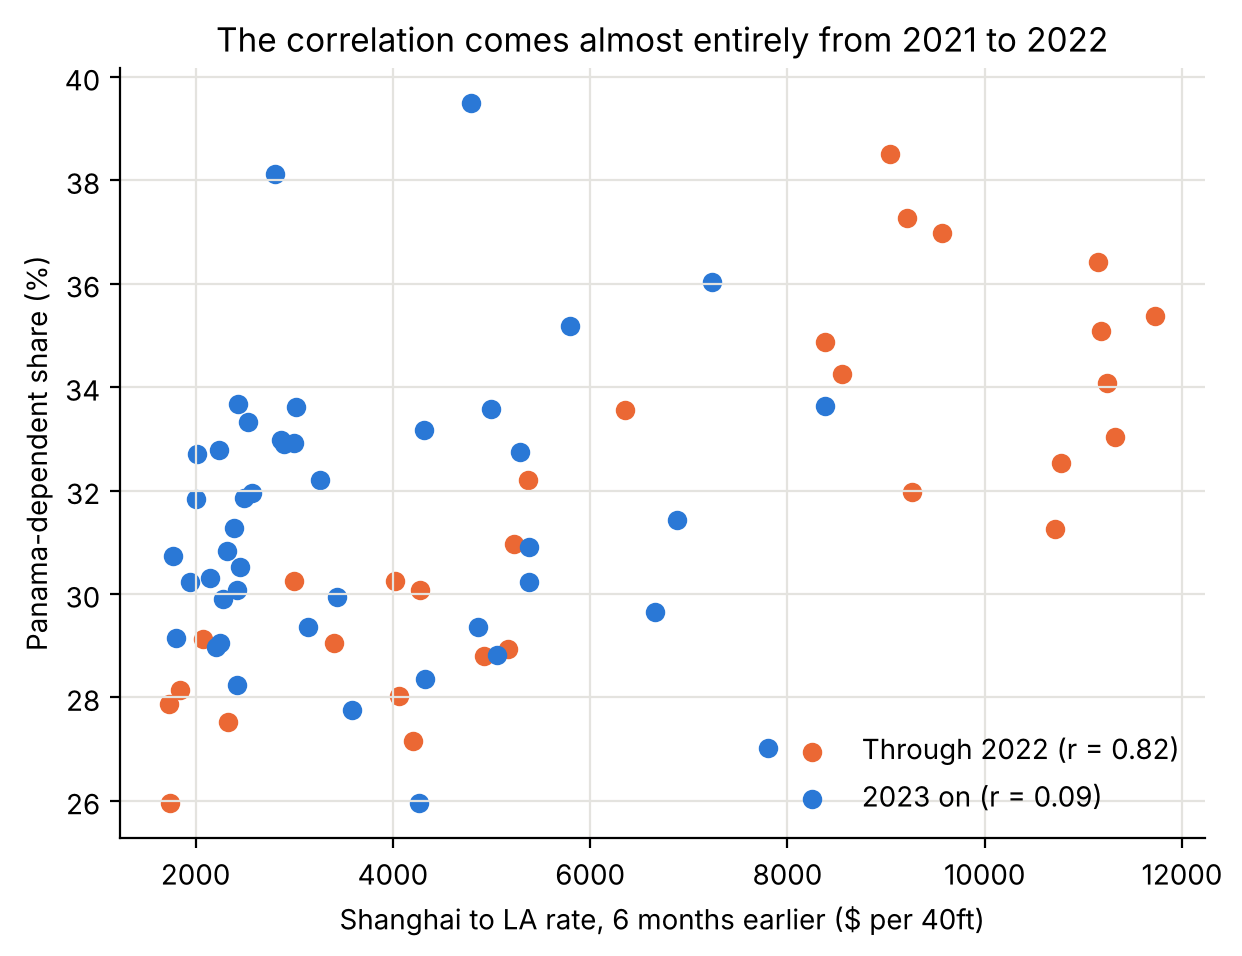

In [30]:
# ---- 8c. Does the relationship hold in both halves of the data? ----------------------
LAG = 6
SPLIT = "2023-01-01"   # before = the 2021-22 congestion era, after = everything since

# Build the lag-6 pair once.
shifted = rate.copy()
shifted.index = shifted.index + pd.DateOffset(months=LAG)
pair = pd.concat([shifted.rename("rate_6mo_earlier"), panama_share.rename("panama_share")],
                 axis=1, join="inner").dropna()

# Split into two eras and correlate each separately.
early = pair[pair.index < SPLIT]
late = pair[pair.index >= SPLIT]
r_all = pair.corr().iloc[0, 1]
r_early = early.corr().iloc[0, 1]
r_late = late.corr().iloc[0, 1]
print(f"All months:        r = {r_all:.2f}  (n = {len(pair)})")
print(f"Through Dec 2022:  r = {r_early:.2f}  (n = {len(early)})")
print(f"From Jan 2023 on:  r = {r_late:.2f}  (n = {len(late)})")

# Scatter, colored by era, so the split is visible.
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(early["rate_6mo_earlier"], early["panama_share"], color=ORANGE, label=f"Through 2022 (r = {r_early:.2f})")
ax.scatter(late["rate_6mo_earlier"], late["panama_share"], color=BLUE, label=f"2023 on (r = {r_late:.2f})")
ax.set_xlabel("Shanghai to LA rate, 6 months earlier ($ per 40ft)")
ax.set_ylabel("Panama-dependent share (%)")
ax.set_title("The correlation comes almost entirely from 2021 to 2022")
ax.legend(frameon=False)
plt.show()

In [31]:
# ---- 8d. Are the observations independent? (They are not.) -----------------------------
# Autocorrelation at lag 1 = how strongly each month resembles the previous month.
print(f"Month-to-month autocorrelation (lag 1):")
print(f"  freight rate:           {rate.autocorr(1):.2f}")
print(f"  GSCPI:                  {gscpi_m.autocorr(1):.2f}")
print(f"  Panama-dependent share: {panama_share.autocorr(1):.2f}")

# A fairer test: correlate month-to-month CHANGES instead of levels, which removes the shared trend.
d_pair = pd.concat([shifted.diff().rename("d_rate"), panama_share.diff().rename("d_share")],
                   axis=1, join="inner").dropna()
print(f"\nCorrelation of monthly changes at a 6-month lag: r = {d_pair.corr().iloc[0, 1]:.2f}  (n = {len(d_pair)})")

Month-to-month autocorrelation (lag 1):
  freight rate:           0.95
  GSCPI:                  0.94
  Panama-dependent share: 0.49

Correlation of monthly changes at a 6-month lag: r = 0.14  (n = 72)


**How much to trust it.** Three checks all point the same way:

1. **One era drives it.** Through 2022 the correlation is strong (about 0.82); since 2023 it is close to zero (about 0.09).
2. **The data are not independent.** The freight rate and GSCPI are very smooth (month-to-month autocorrelation about 0.95), and the lane share is moderately so (about 0.49), so 73 monthly points carry far less information than 73 independent ones. We did not run a significance test, because the usual tests assume independence.
3. **Changes tell a weaker story than levels.** When we correlate month-to-month *changes* at the same six-month lag, r falls to about 0.14. Levels that trend together look related even when their changes are not.

So we describe the freight rate as a **possible lead worth watching**, not a forecast. The rate rose from about $3.1k in April 2026 to about $7.8k in September 2026; if the 2021 to 2022 pattern held, that would point toward an eastward shift in early 2027, but with a post-2023 correlation near zero we would not predict it.

## 9. Datasets we explored but did not use

Three Census files sit in `data/processed/` from the early validation work. We looked at them and decided they did not answer our question. Documenting why is part of the exploration.

In [32]:
# ---- 9a. US imports from China by HS2 commodity chapter ------------------------------
# HS2 is a 2-digit product category. Add a few readable names for the biggest chapters.
HS2_NAMES = {85: "Electrical machinery & electronics", 84: "Machinery & computers",
             94: "Furniture & bedding", 95: "Toys & sports goods", 39: "Plastics",
             87: "Vehicles", 73: "Iron & steel articles", 61: "Knit apparel",
             62: "Woven apparel", 90: "Optical & medical instruments", 64: "Footwear"}

# Use 2024 as a full recent year. "month" is text like "2024-05", so a string prefix filter works.
c24 = china_hs2[(china_hs2["month"].str.startswith("2024")) & (china_hs2["hs_level"] == "HS2")]

# Total 2024 value by chapter, largest first, with each chapter's share of the total.
top = (c24.groupby("hs_code")["total_value_usd"].sum().sort_values(ascending=False).head(8)
          .to_frame("value_usd"))
top["share_%"] = (top["value_usd"] / c24["total_value_usd"].sum() * 100).round(1)
top["chapter"] = [HS2_NAMES.get(int(c), "") for c in top.index]
display(top)
print(f"All-chapter total, 2024: ${c24['total_value_usd'].sum() / 1e9:,.0f} billion")

,value_usd,share_%,chapter
hs_code,,,
85,125572819780,28.50,Electrical machinery & electronics
84,81990754625,18.60,Machinery & computers
95,29970231420,6.80,Toys & sports goods
39,19293462154,4.40,Plastics
94,18605407108,4.20,Furniture & bedding
87,16830834941,3.80,Vehicles
73,11955321184,2.70,Iron & steel articles
90,11808961290,2.70,Optical & medical instruments


All-chapter total, 2024: $440 billion


In [33]:
# ---- 9b. US exports to Mexico: how much goes by sea? ----------------------------------
# Add up value by month, then see what portion is vessel (ship) cargo versus the total.
mx = mexico_hs2.groupby("month")[["total_value_usd", "vessel_value_usd"]].sum()
mx["vessel_share_%"] = mx["vessel_value_usd"] / mx["total_value_usd"] * 100
print(f"Vessel share of US exports to Mexico, monthly average: {mx['vessel_share_%'].mean():.1f}% "
      f"(range {mx['vessel_share_%'].min():.1f}% to {mx['vessel_share_%'].max():.1f}%)")

Vessel share of US exports to Mexico, monthly average: 10.9% (range 6.3% to 18.1%)


In [34]:
# ---- 9c. The brief's example call: all US exports, April 2013 --------------------------
# This file is a single month, kept only to confirm we can call the API the way the course brief shows.
print("Months in the file:", exports_all["month"].unique())
display(exports_all[exports_all["hs_level"] == "-"].head(1))

Months in the file: <StringArray>
['2013-04']
Length: 1, dtype: str


,month,hs_code,hs_description,hs_level,total_value_usd,vessel_value_usd,air_value_usd,shipment_count
0,2013-04,-,TOTAL EXPORTS FOR ALL COMMODITIES,-,129460620838,46656507175,36164286526,3078272


**Why we left these out.**

- **China by HS2 commodity** is useful context (electronics and machinery make up about 47% of the roughly $440 billion of 2024 imports), but our question is about *routes and ports*, not products, and the field names for commodity do not map to a lane.
- **Mexico exports** are mostly moved by truck and rail. Only about 11% of the value goes by vessel on average, so Mexico is not a Panama Canal lane and cannot test route resilience.
- **The April 2013 example call** is a single month and predates our 2019 window. It only confirms the API works.

The decision to use **China-origin cargo by US port of unlading** came from this exploration: it is the one Census cut that tells us *where* ocean cargo landed, month by month, at the same nine ports BTS reports on.

## 10. Findings and limits

### What the exploration told us

1. **The three sources line up well enough to compare.** All have a monthly (or monthly-roll-up) series from January 2019. The weekly BTS series are rolled to monthly means, and port volumes are indexed to each port's own 2019 average so ports of different size can share a scale.
2. **Only two windows are real pressure events.** The 2021 to 2022 congestion window (peak 4.43, above +1 in all 24 months) is far outside anything in 28 years of history apart from April 2020. The 2026 window peaks at 1.81 and is still running. The Panama drought and Red Sea windows barely move the global index (peak 0.20), so they needed lane and port data to see at all.
3. **Cargo shifts are modest except in 2021 to 2022.** The Panama-dependent share moved +8.4 points in the congestion window and about −2 to −3 points in the Red Sea and 2026 windows. The 2019 standard deviation is 1.5 points, so the small shifts are visible but not dramatic.
4. **Congestion and slumps are different things.** Ships waiting peaked at LA-Long Beach (about 103) in early 2022, but the deepest throughput slumps came in 2023, partly from weaker demand. We pair the two measures instead of reading either alone.
5. **The freight-rate lead is fragile.** r = 0.48 at six months, but 0.82 through 2022 and 0.09 since. It is one episode, not a stable rule.

### Design choices this exploration drove

| Finding | Choice in the Tableau Story |
|---|---|
| Containerized value tracks ocean routing; total value includes about 29% air | Lane share uses containerized value |
| Single months are noisy | Bold 3-month average over faint raw months |
| Ports differ in size | Index each port to its own 2019 average (= 100) |
| Backlog has a missing month and a partial last month | Show the gap as a break, drop the partial month |
| Two windows overlap | Show them on separate strip rows and flag overlap months |
| Pressure score barely moves in two windows | Add lane share and ports to the story |

### Limits to state out loud

- **Four episodes support a pattern, not proof.** Two of them overlap in time and cannot be separated.
- **China only.** The lane data is China-origin cargo only. Our deck puts China at about 13% of US goods imports in 2024 and about 8% in 2026 (those totals are not in this repo, so this notebook does not recompute them). Other origins may behave differently, and Mexico, the largest source, moves mostly by truck and rail.
- **Coverage.** The nine mapped ports carry about 93% of China's containerized import value, so the two lane lines add to about 93%, not 100%.
- **BTS ships-waiting is only split into three groups** and starts in July 2021, so it cannot show congestion before then or at individual ports other than LA-Long Beach and Savannah.
- **Revisions.** GSCPI history is revised with each release, and BTS and Census figures are updated. The snapshots are frozen at 15 Oct 2026.
- **Correlation is not cause.** Demand swings, tariffs, and carrier decisions also move these series.

### Next steps (if we had more time)

- Repeat the lane analysis for a second origin country (for example Vietnam or India).
- Use a method that accounts for time-series dependence before testing any lead-lag claim.
- Add a demand control (for example US retail inventories) to separate congestion from weak demand.